# Notebook summary

**Principle.** The network predicts each time bin from the last $D$ bins of activity only (the spiking motif window), $s(t) = f\big(s(t-D), \dots, s(t-1)\big)$, where $D$ = `num_delay` (41 bins of 1 ms) and $s^*$ = `frozen_target` is the motif of $T$ = `N_time` bins (1000 bins). The motif is made periodic by copying its first $D$ bins onto its last $D$ bins:

$$ s^*(t) = s^*(t - P) \quad \text{for } T - D \le t < T, \qquad P = T - D \ (959 \text{ bins}). $$

Training on a single motif covers the $P$ transitions $t \in [D, T)$, which are exactly all the transitions of a cycle of period $P$, including the one that wraps the end of the motif back onto its beginning. Once the network reaches the end of the motif, the window of its last $D$ bins is therefore identical to the trigger window, so it replays $s^*(D), s^*(D+1), \dots$ again: the polychronous chain closes on itself and the motif becomes a self-sustained cycle. Retrieval is then tested over `N_repeat` = 30 consecutive periods after a single trigger window, and the last sweep measures, through the F1 score of each of `N_period` = 100 periods of free replay, how long the cycle survives when each emitted spike fails to reach the recurrent input with probability $p_\mathrm{drop}$.

This notebook trains MNESIS/HD-SNN on periodic spike patterns and evaluates robustness to input perturbations.

## Pipeline
1. Load the shared setup from `mnesis_boilerplate` and `mnesis_chains`.
2. Build `PeriodicSpikingPattern`: Bernoulli target (`p_A`) with periodic boundary copy over `num_delay` bins;
   as a `StochasticSpikingPattern`, each call returns a balanced-flip realisation (`p_flip`).
3. Instantiate `Params` + `HD_SNN`, then load or train and cache `{datetag}_{exp}.pth` (with lock file).
4. Evaluate one-period retrieval (precision, recall, F1) and plot raster diagnostics.
5. Evaluate long-horizon retrieval over repeated periods (`N_repeat`).
6. Same long-horizon retrieval in a second cache (the `flip_bits(..., 0.323)` perturbation is
   commented out, so the trigger is clean).
7. Sweep the transmission failures (`p_drop`, 0 then log-spaced from 1e-4 to 1e-2, `N_scan` = 5 levels,
   `N_cv` = 5 seeded realisations): one noisy trigger, then `N_period` periods (of `N_time - num_delay`
   bins) of free replay with failures, each period scored against the frozen target (precision, recall
   and F1, `scores_np`, shape `(N_scan, N_cv, N_period, 3)`), and compared with the survival
   `exp(-h t)` predicted by `get_replay_hazard`.

## Main outputs
- Model checkpoint: `{datetag}_{exp}.pth`.
- Optional cached spikes: clean/noisy periodic retrieval tensors.
- Failure-sweep cache: `{datetag}_{exp}-drop_N_scan={N_scan}_N_cv={N_cv}_N_period={N_period}.npz` (`p_drop`, `scores_np`, `n_done`).
- Metrics and plots: precision/recall/F1, rasters, and F1-vs-period trajectories.

In [1]:
from mnesis_boilerplate import torch, np, plt, splt, data_cache, cache_lock, RECOMPUTE, Params
from mnesis_boilerplate import printfig, get_scores, get_f1_from_ignition, get_replay_hazard, trange
from mnesis_chains import HD_SNN, StochasticSpikingPattern
# RECOMPUTE = True
exp = 'periodic'

datetag = '2026-09-07'
Using device: mps


## working memory with periodic targets

Setting up:

In [2]:
# (p_flip) as notebook 11; the periodic wrap is restored after each realisation.
class PeriodicSpikingPattern(StochasticSpikingPattern):
    def __init__(self):
        super().__init__()
        self.desc = "Periodic pattern generator"
        self.is_periodic = True

    def init(self, opt, verbose=False):
        self.opt = opt
        frozen_target_generator = torch.Generator()  # used once to generate the target pattern
        frozen_target_generator.manual_seed(opt.seed)
        p_bias = opt.p_A * torch.ones((opt.N_pattern, opt.N_neuron, opt.N_time))
        self.frozen_target = torch.bernoulli(p_bias, generator=frozen_target_generator)
        self.frozen_target = self.frozen_target.float()
        self.frozen_target = self.frozen_target.to(opt.device)
        if verbose:
            print(f"Target pattern generated with shape {self.frozen_target.shape} and mean {self.frozen_target.mean().item():.3e}")

        # Make the target periodic by copying the first opt.num_delay time steps to the end of the sequence
        # such that the polychronous chain is virtually endless
        self.frozen_target[:, :, (-opt.num_delay):] = self.frozen_target[:, :, :opt.num_delay]

    def __call__(self, seed=None, verbose=False):
        realisation = super().__call__(seed=seed, verbose=verbose)
        # keep the chain endless: the last num_delay bins repeat the first ones
        realisation[:, :, (-self.opt.num_delay):] = realisation[:, :, :self.opt.num_delay]
        return realisation


In [3]:
opt = Params()
hd = HD_SNN(opt, PeriodicSpikingPattern())
hd.net.to(hd.opt.device)
hd.pattern_object().shape, opt

(torch.Size([16, 1024, 1000]),
 Params(datetag='2026-09-07', N_neuron=1024, num_delay=41, N_pattern=16, N_time=1000, N_pretime=50, p_A=0.00016, p_flip=0.01, seed=2026, lif_beta=0.7, lif_threshold=0.75, learn_beta=False, learn_threshold=False, do_pinv=True, do_deconv=True, num_epochs=256, num_warmup_epochs=16, base_lr=0.04, final_lr=0.0004, delta1=0.003, delta2=1e-05, dropout=0.6, alpha_surrogate=5.0, surrogate_name='FastSigmoid', loss_name='SpikeF1scoreLoss', reset_mechanism='zero', optimizer='adadelta', verbose=False, fig_width=15.92, phi=1.61803, fig_height=9.839125356142963, N_time_show=1000, N_neuron_show=1024, i_pattern=1, N_scan=14, N_cv=11))

## Learn the periodic target

In [4]:
model_filename = data_cache / f"{hd.opt.datetag}_{exp}.pth"
lock_filename = model_filename.with_suffix('.lock')
if RECOMPUTE:
    model_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
    lock_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
try:
    model_state_dict = torch.load(model_filename, map_location=torch.device(hd.opt.device))
    hd.net.load_state_dict(model_state_dict)
    hd.net.eval()
    lock_filename.unlink(missing_ok=True) # in case the lock file was not unlinked
    print(f"Model weights loaded from {model_filename}") # Add a log message
except FileNotFoundError:
    with cache_lock(model_filename) as acquired:
        if acquired:
            print(f"Model file not found: {model_filename}, inititializing and learning the new model.")
            ##################
            hd.update_weight()
            hd.learn_model()
            ##################
            torch.save(hd.net.state_dict(), model_filename)
        else:
            print(f"Model file is locked: {lock_filename}, passing.")

Model weights loaded from ../cached_data/2026-09-07_periodic.pth


In [5]:
with torch.no_grad():
    target = hd.pattern_object.frozen_target # noise-free reference, scored against
    cue = hd.pattern_object(seed=hd.opt.seed) # seeded noisy realisation, provides the trigger
    target_full = torch.nn.functional.pad(target, (opt.N_pretime, opt.N_pretime))
    input_spikes = hd.get_input_spikes(target=cue, seed=hd.opt.seed)
    _, _, spikes = hd.forward_pass(input_spikes)
    spikes_evoked = spikes[:, :, (hd.opt.N_pretime+hd.opt.num_delay):(hd.opt.N_time+hd.opt.N_pretime)]
    target_evoked = target[:, :, hd.opt.num_delay:]

    precision, recall, f1_score = get_scores(spikes_evoked, target_evoked)
    print(f'precision = {precision:.3f}\t recall = {recall:.3f}\t f1_score = {f1_score:.3f} ')

precision = 0.828	 recall = 0.826	 f1_score = 0.827 


(torch.Size([16, 1024, 1100]), 171.0, 169.0)

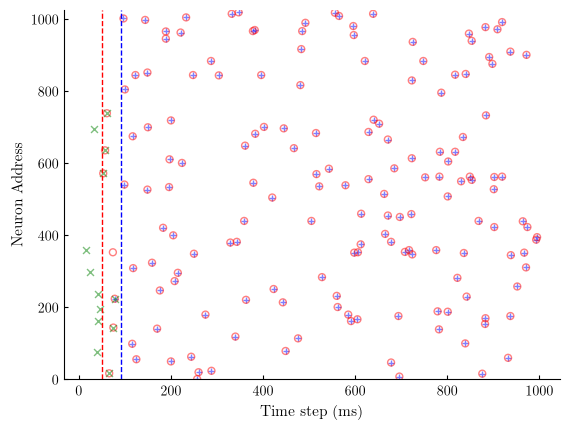

In [6]:
fig, ax = plt.subplots()
splt.raster(spikes[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].T, ax, s=25, c="blue", marker='+', alpha=.5)
splt.raster(target_full[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].T, ax, s=25, facecolor='none', edgecolor='red',  marker='o', alpha=.5)
splt.raster(input_spikes[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].T, ax, s=25, c="green", marker='x', alpha=.5)
ax.vlines([opt.N_pretime], 0, opt.N_neuron_show, 'r', ls='--')
ax.vlines([opt.N_pretime+opt.num_delay], 0, opt.N_neuron_show, 'b', ls='--')
ax.set_xlabel("Time step (ms)")
ax.set_ylabel("Neuron Address")
ax.set_ylim(-1., opt.N_neuron_show + 1.)
spikes.shape, spikes[opt.i_pattern, :, :].sum().item(), target[opt.i_pattern, :, :].sum().item()

## Retrieve a periodic memory

In [7]:
N_repeat = 30

In [8]:
target.shape

torch.Size([16, 1024, 1000])

In [9]:
spikes_filename = data_cache / f"{hd.opt.datetag}_{exp}_spikes.pth"
lock_filename = spikes_filename.with_suffix('.lock')

if RECOMPUTE:
    spikes_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
    lock_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
with torch.no_grad():    
    target_full = torch.nn.functional.pad(target[:, :, :(-hd.opt.num_delay)].repeat(1, 1, N_repeat), (opt.N_pretime, opt.N_pretime))
    input_spikes = hd.get_input_spikes(target=target, N_time=N_repeat*(opt.N_time-opt.num_delay))
    try:
        spikes = torch.load(spikes_filename, map_location=torch.device(hd.opt.device))
        lock_filename.unlink(missing_ok=True) # in case the lock file was not unlinked
        print(f"Model weights loaded from {spikes_filename}") # Add a log message
    except FileNotFoundError:
        with cache_lock(spikes_filename) as acquired:
            if acquired:
                print(f"Spikes file not found: {spikes_filename}, running the model.")
                ##################
                _, _, spikes = hd.forward_pass(input_spikes)
                ##################
                torch.save(spikes, spikes_filename)
            else:
                print(f"Model file is locked: {lock_filename}, passing.")
    spikes_evoked = spikes[:, :, (hd.opt.N_pretime+hd.opt.num_delay):(hd.opt.N_time+hd.opt.N_pretime)]
    target_evoked = target_full[:, :, (hd.opt.N_pretime+hd.opt.num_delay):(hd.opt.N_time+hd.opt.N_pretime)]
    
    precision, recall, f1_score = get_scores(spikes_evoked, target_evoked)
    print(f'precision = {precision:.3f}\t recall = {recall:.3f}\t f1_score = {f1_score:.3f} ')

Model weights loaded from ../cached_data/2026-09-07_periodic_spikes.pth
precision = 0.940	 recall = 0.827	 f1_score = 0.880 


In [10]:
target_full.shape, input_spikes.shape, spikes.shape

(torch.Size([16, 1024, 28870]),
 torch.Size([16, 1024, 28870]),
 torch.Size([16, 1024, 28870]))

(torch.Size([16, 1024, 28870]), 4863.0, 169.0)

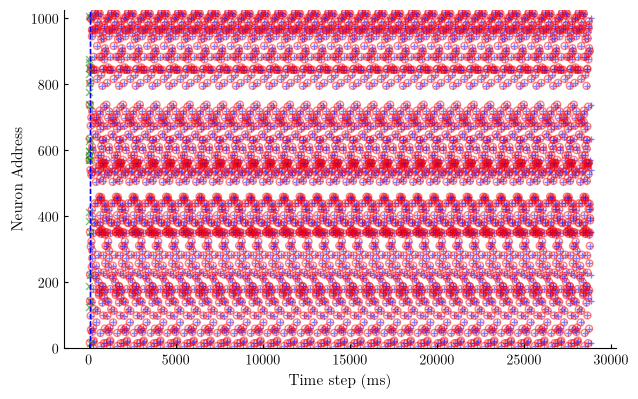

In [11]:
fig, ax = plt.subplots()
splt.raster(spikes[opt.i_pattern, :opt.N_neuron_show, :].T, ax, s=25, c="blue", marker='+', alpha=.5)
splt.raster(target_full[opt.i_pattern, :opt.N_neuron_show, :].T, ax, s=25, facecolor='none', edgecolor='red',  marker='o', alpha=.5)
splt.raster(input_spikes[opt.i_pattern, :opt.N_neuron_show, :].T, ax, s=25, c="green", marker='x', alpha=.5)
ax.vlines([opt.N_pretime], 0, opt.N_neuron_show, 'r', ls='--')
ax.vlines([opt.N_pretime+opt.num_delay], 0, opt.N_neuron_show, 'b', ls='--')
ax.set_xlabel("Time step (ms)")
ax.set_ylabel("Neuron Address")
ax.set_ylim(-1., opt.N_neuron_show + 1.)
printfig(fig, 'periodic_spikes', fig_width=opt.fig_width, fig_height=opt.fig_height, figpath=None)
spikes.shape, spikes[opt.i_pattern, :, :].sum().item(), target[opt.i_pattern, :, :].sum().item()

## Retrieve a periodic memory with a little bit of noise

In [12]:
spikes_filename = data_cache / f"{hd.opt.datetag}_{exp}_spikes_noisy.pth"
lock_filename = spikes_filename.with_suffix('.lock')
# RECOMPUTE = True
if RECOMPUTE:
    spikes_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
    lock_filename.unlink(missing_ok=True) # FORCING RECOMPUTE

with torch.no_grad():    
    target_full = torch.nn.functional.pad(target[:, :, :(-hd.opt.num_delay)].repeat(1, 1, N_repeat), (opt.N_pretime, opt.N_pretime))
    input_spikes = hd.get_input_spikes(target=target, N_time=N_repeat*(opt.N_time-opt.num_delay))
    # input_spikes = flip_bits(input_spikes, .323, seed=hd.opt.seed)  # Add a seed for reproducibility
    try:
        spikes = torch.load(spikes_filename, map_location=torch.device(hd.opt.device))
        lock_filename.unlink(missing_ok=True) # in case the lock file was not unlinked
        print(f"Model weights loaded from {spikes_filename}") # Add a log message
    except FileNotFoundError:
        with cache_lock(spikes_filename) as acquired:
            if acquired:
                print(f"Spike file not found: {spikes_filename}, running the model.")
                ##################
                _, _, spikes = hd.forward_pass(input_spikes)
                ##################
                torch.save(spikes, spikes_filename)
            else:
                print(f"Model file is locked: {lock_filename}, passing.")
    spikes_evoked = spikes[:, :, (hd.opt.N_pretime+hd.opt.num_delay):(hd.opt.N_time+hd.opt.N_pretime)]
    target_evoked = target_full[:, :, (hd.opt.N_pretime+hd.opt.num_delay):(hd.opt.N_time+hd.opt.N_pretime)]
    
    precision, recall, f1_score = get_scores(spikes_evoked, target_evoked)
    print(f'precision = {precision:.3f}\t recall = {recall:.3f}\t f1_score = {f1_score:.3f} ')


Model weights loaded from ../cached_data/2026-09-07_periodic_spikes_noisy.pth
precision = 0.933	 recall = 0.827	 f1_score = 0.876 


In [13]:
target_full.shape, spikes.shape, input_spikes.shape

(torch.Size([16, 1024, 28870]),
 torch.Size([16, 1024, 28870]),
 torch.Size([16, 1024, 28870]))

(torch.Size([16, 1024, 28870]), 4863.0, 169.0)

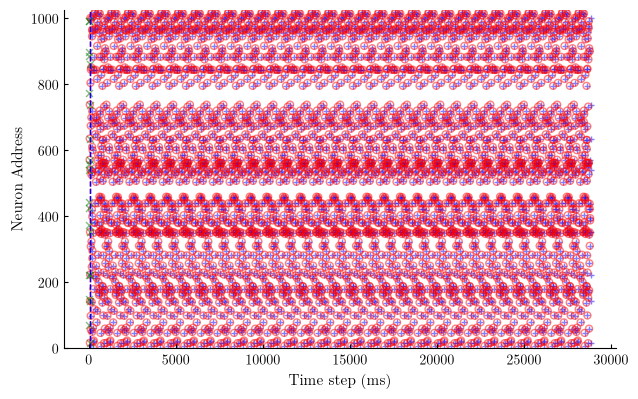

In [14]:
fig, ax = plt.subplots()
splt.raster(spikes[opt.i_pattern, :opt.N_neuron_show, :].T, ax, s=25, c="blue", marker='+', alpha=.5)
splt.raster(target_full[opt.i_pattern, :opt.N_neuron_show, :].T, ax, s=25, facecolor='none', edgecolor='red',  marker='o', alpha=.5)
splt.raster(input_spikes[opt.i_pattern, :opt.N_neuron_show, :].T, ax, s=25, c="green", marker='x', alpha=.5)
ax.vlines([opt.N_pretime], 0, opt.N_neuron_show, 'r', ls='--')
ax.vlines([opt.N_pretime+opt.num_delay], 0, opt.N_neuron_show, 'b', ls='--')
ax.set_xlabel("Time step (ms)")
ax.set_ylabel("Neuron Address")
ax.set_ylim(-1., opt.N_neuron_show + 1.)
printfig(fig, 'periodic_spikes_noise', fig_width=opt.fig_width, fig_height=opt.fig_height, figpath=None)
spikes.shape, spikes[opt.i_pattern, :, :].sum().item(), target[opt.i_pattern, :, :].sum().item()

(torch.Size([16, 1024, 28870]), torch.Size([16, 1024, 28870]))

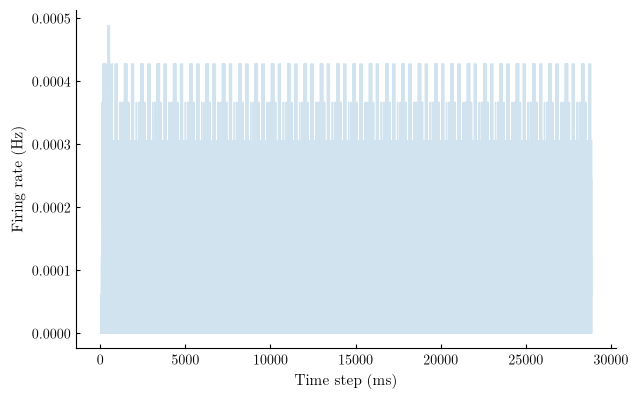

In [15]:
fig, ax = plt.subplots()
ax.plot(spikes.mean(dim=[0, 1]).cpu(), alpha=.2)
# ax.plot(spikes[opt.i_pattern, ...].mean(dim=0).cpu(), alpha=.7)
ax.set_xlabel("Time step (ms)")
ax.set_ylabel("Firing rate (Hz)")
printfig(fig, 'periodic_firing', fig_width=opt.fig_width, fig_height=opt.fig_height, figpath=None)
spikes.shape, target_full.shape

## Long-horizon replay under spike transmission failures

After a single seeded trigger window, each spike emitted by the network fails to reach the recurrent input with probability $p_\mathrm{drop}$ (`reset_spikes` of `forward_pass`), at every step of the `N_period` periods of free replay. In the cascade picture, every spike of a motif is then a new ignition test, so that the replay survives $t$ steps with probability $e^{-h t}$, with the failure rate $h$ of `get_replay_hazard`.

In [ ]:
N_period = 100 # number of periods of free replay after the trigger window
# fewer levels and realisations than opt.N_scan and opt.N_cv: each run lasts about 70 s on MPS,
# so that the 25 runs of the sweep take about 30 min
N_scan, N_cv = 5, 5
# no failure, then log-spaced failure probabilities, from a lifetime of a few hundred periods
# down to a few periods (get_replay_hazard); changing this grid requires RECOMPUTE
p_drop = np.concatenate([[0.], np.geomspace(1e-4, 1e-1, N_scan - 1)])

def get_scores_drop(p_drop=p_drop, N_cv=N_cv, N_period=N_period):
    # the last num_delay bins of the motif repeat the first ones, so the chain has this period (bins)
    period = hd.opt.N_time - hd.opt.num_delay
    # the evoked window starts at phase num_delay of the motif, so every period is scored
    # against the same slice as the one-period score above
    target_evoked = target[:, :, hd.opt.num_delay:]
    t_evoked = hd.opt.N_pretime + hd.opt.num_delay
    scores_np = np.zeros((len(p_drop), N_cv, N_period, 3)) # precision, recall and F1 of each period
    i_start = 0
    if npy_filename.exists(): # resume after the last complete level: each realisation has its own seeds
        data = np.load(npy_filename)
        if data['scores_np'].shape == scores_np.shape:
            scores_np, i_start = data['scores_np'], int(data['n_done'])
    for i_scan in trange(i_start, len(p_drop)):
        for i_cv in range(N_cv):
            seed = hd.opt.seed + N_cv * i_scan + i_cv # one seed per realisation (nb 20 convention)
            with torch.no_grad():
                # seeded noisy trigger at the default p_flip, as for the one-period score above
                cue = hd.pattern_object(seed=seed)
                input_spikes = hd.get_input_spikes(target=cue, N_time=hd.opt.num_delay + N_period*period, seed=seed)
                # transmission failures: each spike emitted after the trigger window is removed from the
                # recurrent input with probability p_drop; drawn on the CPU on a seed stream of its own
                # (streams 1 and 2 are the flips and the spontaneous pad), then sent to the device
                generator = torch.Generator().manual_seed(int(np.random.SeedSequence([seed, 3]).generate_state(1)[0]))
                reset_spikes = torch.bernoulli(torch.full(input_spikes.shape, p_drop[i_scan]), generator=generator)
                reset_spikes[:, :, :t_evoked] = 0 # the trigger window is left intact
                _, _, spikes = hd.forward_pass(input_spikes, reset_spikes=reset_spikes.to(hd.opt.device))

                for i_period in range(N_period):
                    spikes_evoked = spikes[:, :, (t_evoked + i_period*period):(t_evoked + (i_period+1)*period)]
                    scores_np[i_scan, i_cv, i_period] = [score.item() for score in get_scores(spikes_evoked, target_evoked)]

        np.savez(npy_filename, p_drop=p_drop, scores_np=scores_np, n_done=i_scan + 1) # incremental save

    return scores_np

# the grid, the number of realisations and the length of the run belong to the cache key
npy_filename = data_cache / f"{hd.opt.datetag}_{exp}-drop_N_scan={N_scan}_N_cv={N_cv}_N_period={N_period}.npz"
lock_filename = npy_filename.with_suffix('.lock')
# RECOMPUTE = True
if RECOMPUTE:
    npy_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
    lock_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
try:
    data = np.load(npy_filename)
    scores_np = data['scores_np']
    if scores_np.shape != (N_scan, N_cv, N_period, 3) or int(data['n_done']) != N_scan:
        raise ValueError(f"Partial score file: {npy_filename}, resuming.")
    lock_filename.unlink(missing_ok=True) # in case the lock file was not unlinked
    print(f"Scores loaded from {npy_filename}")
except (FileNotFoundError, ValueError):
    with cache_lock(npy_filename) as acquired:
        if acquired:
            print(f"Score file not found or partial: {npy_filename}, evaluating the score.")
            ##################
            scores_np = get_scores_drop()
            ##################
        else:
            print(f"Score file is locked: {lock_filename}, passing.")

Score file not found or partial: ../cached_data/2026-09-07_periodic-drop_N_scan=5_N_cv=5_N_period=100.npz, evaluating the score.


100%|██████████| 5/5 [43:01<00:00, 516.39s/it]


Saving as ../figures/periodic_scores.pdf
Saving as ../figures/periodic_scores.png
Saving as ../figures/periodic_scores.svg


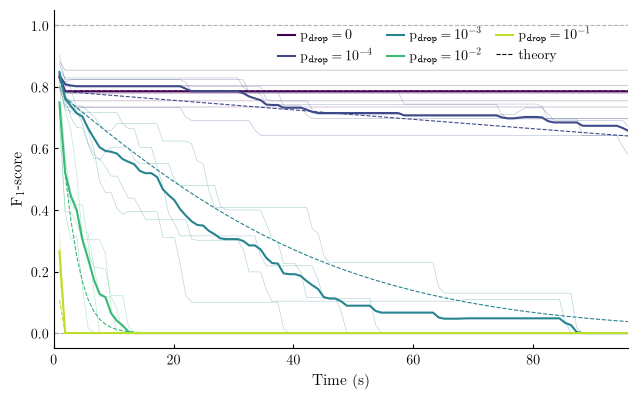

In [32]:
# F1 of each period against time: thin lines for the realisations, thick line for their mean, and
# dashed line for the theory: the replay of a motif survives t steps with probability exp(-h t)
# (get_replay_hazard), averaged over each period, with the precision and recall of the same period
# without failure (the motifs whose replay stops at a gap are already counted in them)
if not lock_filename.exists():
    period = opt.N_time - opt.num_delay
    period_s = period * 1e-3 # time steps of 1 ms: a period lasts about 1 s
    t_end = np.arange(1, N_period+1) * period_s # each period is plotted at the time it ends
    precision_0, recall_0 = scores_np[0, :, :, 0].mean(axis=0), scores_np[0, :, :, 1].mean(axis=0)
    t_steps = np.arange(N_period*period).reshape(N_period, period) # steps since the end of the trigger window
    hazard = get_replay_hazard(p_drop, p_A=opt.p_A, N_neuron=opt.N_neuron, num_delay=opt.num_delay,
                               lif_threshold=opt.lif_threshold)

    fig, ax = plt.subplots()
    colours = plt.cm.viridis(np.linspace(0, .9, N_scan))
    ax.axhline(0, color='0.7', ls='--', lw=0.8) # grey dashed guides at the extremal F1 values
    ax.axhline(1, color='0.7', ls='--', lw=0.8)
    for i_scan in range(N_scan):
        label = r'$p_\mathrm{drop} = 0$' if p_drop[i_scan] == 0 else rf'$p_\mathrm{{drop}} = 10^{{{np.log10(p_drop[i_scan]):.0f}}}$'
        ax.plot(t_end, scores_np[i_scan, :, :, 2].T, color=colours[i_scan], alpha=.4, lw=.4, rasterized=True)
        ax.plot(t_end, scores_np[i_scan, :, :, 2].mean(axis=0), color=colours[i_scan], lw=1.5, label=label)
        survival = np.exp(- hazard[i_scan] * t_steps).mean(axis=1)
        ax.plot(t_end, get_f1_from_ignition(survival, precision_0, recall_0), color=colours[i_scan], ls='--', lw=.8)
    ax.plot([], [], color='k', ls='--', lw=.8, label='theory')
    ax.set_xlabel("Time (s)")
    ax.set_ylabel(r"$F_1$-score")
    ax.set_xlim(0, t_end[-1])
    ax.set_ylim(-0.05, 1.05)
    ax.legend(loc='upper right', ncols=3, bbox_to_anchor=(.95, .975), handlelength=1.2, handletextpad=0.4, borderaxespad=0.2, labelspacing=0.3, columnspacing=1.)
    printfig(fig, 'periodic_scores', fig_width=opt.fig_width, fig_height=opt.fig_height)